# Model Readiness Check of the Training, Validation and Test Sets
**Project Team 7: Customer Churn Analysis (WILDA26_09) | Stage 2, Data Preparation**  
**Prepared by:** Shivani, Data Analyst (Predictive Modelling) | Jira T7-39  
**Input:** the sets prepared by Harjot Kaur (Data Engineer) in `Data_Preparation/train_test_sets/`

This notebook checks that the training, validation and test sets are ready for the churn prediction model built in Stage 3. It records the size and composition of each set, confirms the scaling was done without leakage, counts identical customer profiles across sets, and calculates the class weights the model will use. It does not change Harjot's files and does not train a model.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_class_weight

DATA = "../train_test_sets/"          # Harjot's sets, next to this folder in the repository
os.makedirs("figures", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

train = pd.read_csv(DATA + "ats_train.csv")
val = pd.read_csv(DATA + "ats_val.csv")
test = pd.read_csv(DATA + "ats_test.csv")
sets = {"Training": train, "Validation": val, "Test": test}

## 1. Size and composition of each set

In [2]:
total = sum(len(d) for d in sets.values())
comp = pd.DataFrame({
    "Rows": [len(d) for d in sets.values()],
    "Share (%)": [round(len(d) / total * 100, 1) for d in sets.values()],
    "Churn = 1": [int(d["Churn"].sum()) for d in sets.values()],
    "Churn = 0": [int((d["Churn"] == 0).sum()) for d in sets.values()],
    "Churn rate (%)": [round(d["Churn"].mean() * 100, 1) for d in sets.values()]},
    index=list(sets.keys()))
comp.loc["Total"] = [total, 100.0, comp["Churn = 1"].sum(), comp["Churn = 0"].sum(),
                     round(comp["Churn = 1"].sum() / total * 100, 1)]
comp[["Rows", "Churn = 1", "Churn = 0"]] = comp[["Rows", "Churn = 1", "Churn = 0"]].astype(int)
comp.to_csv("outputs/set_composition.csv")
comp

,Rows,Share (%),Churn = 1,Churn = 0,Churn rate (%)
Training,4930,70.0,1308,3622,26.5
Validation,1056,15.0,280,776,26.5
Test,1057,15.0,281,776,26.6
Total,7043,100.0,1869,5174,26.5


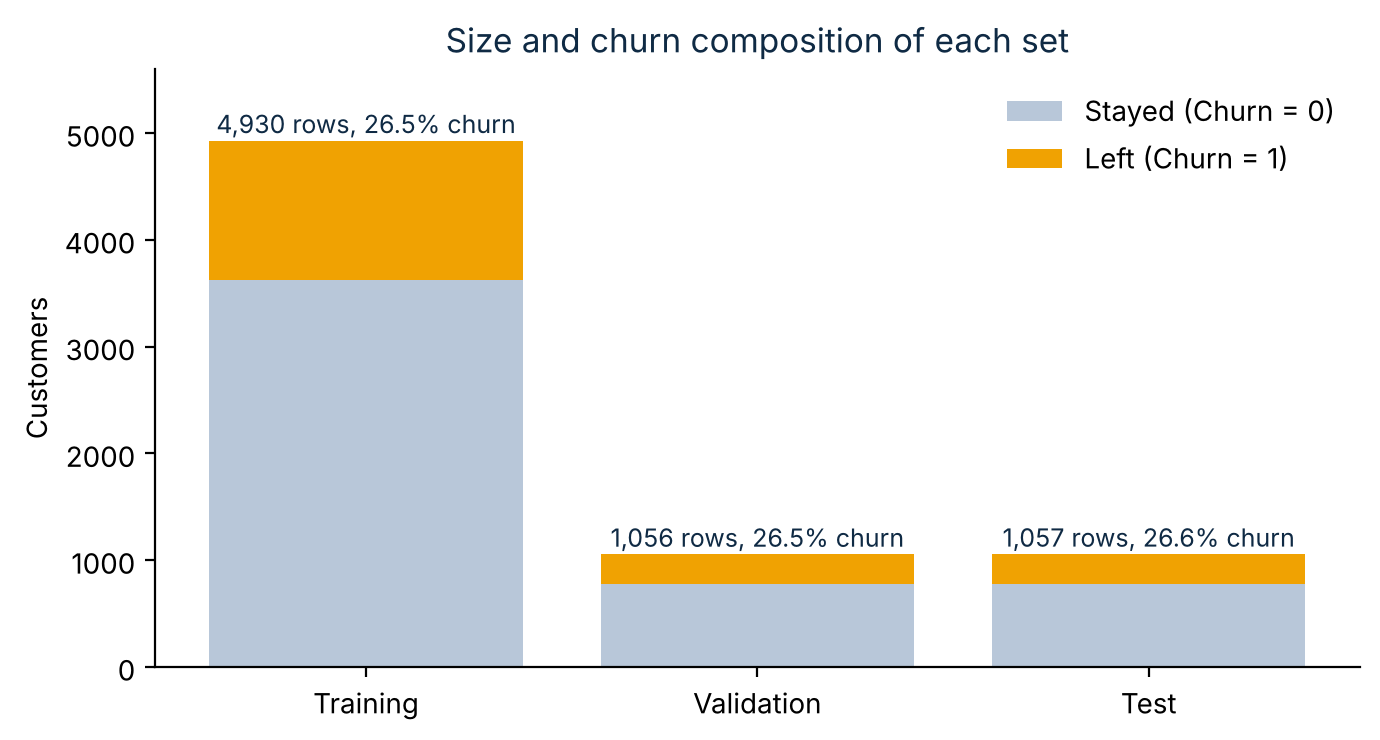

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.8))
names = list(sets.keys())
stay = [int((d["Churn"] == 0).sum()) for d in sets.values()]
leave = [int(d["Churn"].sum()) for d in sets.values()]
ax.bar(names, stay, color="#B8C7D9", label="Stayed (Churn = 0)")
ax.bar(names, leave, bottom=stay, color="#F0A202", label="Left (Churn = 1)")
for i, d in enumerate(sets.values()):
    ax.text(i, len(d) + 70, f"{len(d):,} rows, {d['Churn'].mean()*100:.1f}% churn", ha="center", color="#0F2A44", fontsize=9)
ax.set_ylabel("Customers"); ax.set_ylim(0, 5600)
ax.set_title("Size and churn composition of each set", color="#0F2A44")
ax.legend(frameon=False, loc="upper right"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/set_composition.png", dpi=150); plt.show()

## 2. Columns, data types and missing values

In [4]:
features = [c for c in train.columns if c != "Churn"]
print(len(features), "features + Churn:", features)
print("Same columns in all three sets:", list(train.columns) == list(val.columns) == list(test.columns))
print("Missing values:", {n: int(d.isna().sum().sum()) for n, d in sets.items()})
print("All columns numeric:", all(pd.api.types.is_numeric_dtype(train[c]) for c in train.columns))
print("Churn values:", sorted(int(v) for v in train["Churn"].unique()))

12 features + Churn: ['gender', 'SeniorCitizen', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'MonthlyCharges', 'InternetService_DSL', 'InternetService_Fiber_optic', 'Contract_Month_to_month', 'Contract_One_year', 'Contract_Two_year']
Same columns in all three sets: True
Missing values: {'Training': 0, 'Validation': 0, 'Test': 0}
All columns numeric: True
Churn values: [0, 1]


## 3. Scaling check (no leakage)
Tenure and MonthlyCharges were standardised with the training mean and standard deviation. The training set should show a mean of 0 and a standard deviation of 1; the validation and test sets should be close to that but not exact, because the scaler was not refitted on them.

In [5]:
num = ["tenure", "MonthlyCharges"]
scaling = pd.concat({n: d[num].agg(["mean", "std"]).round(3) for n, d in sets.items()})
scaling.to_csv("outputs/scaling_check.csv")
scaling

tenure  MonthlyCharges
Training   mean   0.000          -0.000
           std    1.000           1.000
Validation mean   0.010           0.039
           std    0.996           1.006
Test       mean   0.006          -0.002
           std    0.998           0.980

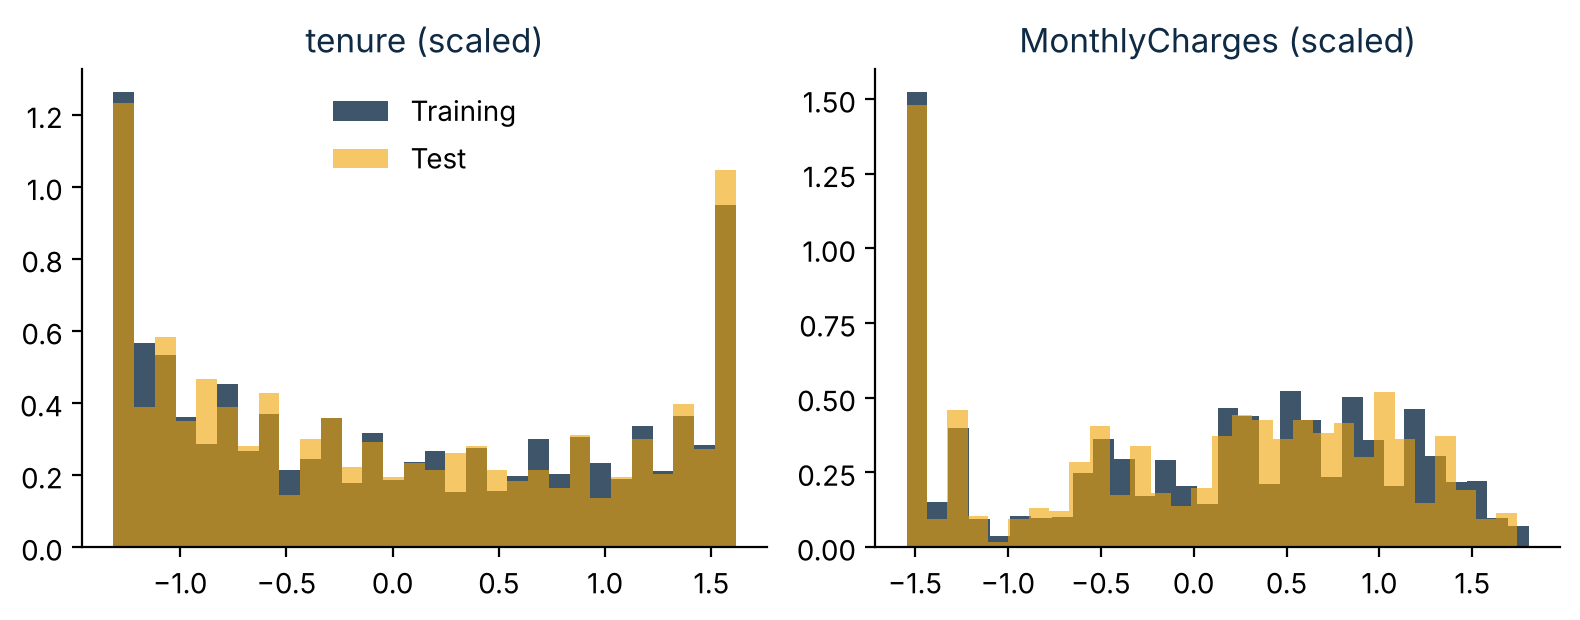

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, col in zip(axes, num):
    ax.hist(train[col], bins=30, alpha=0.8, color="#0F2A44", label="Training", density=True)
    ax.hist(test[col], bins=30, alpha=0.6, color="#F0A202", label="Test", density=True)
    ax.set_title(col + " (scaled)", color="#0F2A44"); ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
plt.tight_layout(); plt.savefig("figures/scaling_check.png", dpi=150); plt.show()

## 4. Identical customer profiles across sets
The team kept the 302 duplicate rows, so some validation and test customers have exactly the same profile as a training customer. They are counted here so they can be reported as a limitation.

In [7]:
key = lambda d: d[features].round(6).astype(str).agg("|".join, axis=1)
train_keys = set(key(train))
overlap = pd.DataFrame({
    "Rows": [len(val), len(test)],
    "Matching a training profile": [int(key(val).isin(train_keys).sum()), int(key(test).isin(train_keys).sum())]},
    index=["Validation", "Test"])
overlap["Share (%)"] = (overlap["Matching a training profile"] / overlap["Rows"] * 100).round(1)
overlap.to_csv("outputs/overlap_check.csv")
overlap

,Rows,Matching a training profile,Share (%)
Validation,1056,81,7.7
Test,1057,82,7.8


## 5. Class weights and naive baseline

In [8]:
w = compute_class_weight("balanced", classes=np.array([0, 1]), y=train["Churn"])
weights = pd.Series({"No churn (0)": round(w[0], 4), "Churn (1)": round(w[1], 4)}, name="weight")
weights.to_csv("outputs/class_weights.csv")
print(weights.to_string())
print(f"Naive baseline on the test set (predict 'no churn' for everyone): "
      f"{(1 - test['Churn'].mean())*100:.1f}% accuracy, 0% recall")

No churn (0)    0.6806
Churn (1)       1.8846
Naive baseline on the test set (predict 'no churn' for everyone): 73.4% accuracy, 0% recall


## 6. Result
- **Size and composition:** 4,930 / 1,056 / 1,057 rows (70 / 15 / 15%), churn rate 26.5%, 26.5% and 26.6%. The stratified split kept the churn balance in every set.
- **Structure:** 12 numeric features plus Churn in every set, identical columns, no missing values.
- **Scaling:** training mean 0 and standard deviation 1; validation and test close to these, confirming no leakage.
- **Limitation:** 81 validation rows (7.7%) and 82 test rows (7.8%) match a training profile because duplicates were kept. Stage 3 results will be reported with and without these rows.
- **Class weights:** 0.6806 for no churn and 1.8846 for churn.

**How the sets will be used in Stage 3:** the training set fits the model, the validation set is used for tuning and early stopping, and the test set is used once for the final evaluation. The sets are ready for modelling.